# CLEARS — Baseline Model Check (T-2.1)
**File:** `notebooks/02_baseline_model.ipynb`  |  **Author:** Person 2 — ML & Explainability Lead

Purpose: prove the pipeline works end to end with simple models *before* the XGBoost work, and give a baseline to beat.
Minimal inputs only: the five raw weather columns, the weather flags, and the label. No time, airport or delay-history features.

**Two pitfalls handled here**
1. `features_final.csv` is sorted by airport and then by time (all MEM rows, then all ORD rows). `train_test_split(shuffle=False)` as written in the task guide would therefore test on the *last 20% of ORD only*. The split below is by **date** instead.
2. `dep_delay`, `arr_delay` and the other delay columns *are* the label (`dep_delay > 15`). They are excluded; including them would give a fake F1 near 1.0.

## 1. Load and split by date

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, classification_report, roc_auc_score, average_precision_score,
                             ConfusionMatrixDisplay)

DATA = next(p for p in [Path('../data/processed/features_final.csv'), Path('data/processed/features_final.csv')] if p.exists())
df = pd.read_csv(DATA, low_memory=False, parse_dates=['flight_date'])

WEATHER = ['wind_speed_knots', 'visibility_km', 'temperature_c', 'humidity_pct', 'precip_mm_hr',
           'visibility_risk', 'storm_flag', 'wind_category_enc', 'rain_severity_enc', 'temp_stress']
TEST_START = pd.Timestamp('2022-02-01')      # whole-date boundary: nothing from 2022-01-31 in both sets
train, test = df[df.flight_date < TEST_START], df[df.flight_date >= TEST_START]
assert train.flight_date.max() < test.flight_date.min()
print('train: %s -> %s  rows=%d  disruption rate=%.3f' % (train.flight_date.min().date(), train.flight_date.max().date(),
                                                          len(train), train.disruption.mean()))
print('test : %s -> %s  rows=%d  disruption rate=%.3f' % (test.flight_date.min().date(), test.flight_date.max().date(),
                                                          len(test), test.disruption.mean()))
print('test airports:', test.airport_code.value_counts().to_dict())
X_train, y_train, X_test, y_test = train[WEATHER], train.disruption, test[WEATHER], test.disruption

train: 2019-01-01 -> 2022-01-31  rows=287475  disruption rate=0.177
test : 2022-04-01 -> 2022-10-31  rows=71119  disruption rate=0.184
test airports: {'ORD': 65891, 'MEM': 5228}


## 2. Train and evaluate the two baselines

In [2]:
models = {
    'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight='balanced')),
    'Decision tree (depth 5)': DecisionTreeClassifier(max_depth=5, min_samples_leaf=200, class_weight='balanced',
                                                      random_state=42),
}
rows, probs = [], {}
for name, m in models.items():
    m.fit(X_train, y_train)
    probs[name] = m.predict_proba(X_test)[:, 1]
    pred = m.predict(X_test)
    rep = classification_report(y_test, pred, output_dict=True, zero_division=0)
    rows.append({'model': name, 'accuracy': accuracy_score(y_test, pred),
                 'precision (disrupted)': rep['1']['precision'], 'recall (disrupted)': rep['1']['recall'],
                 'F1 (disrupted)': rep['1']['f1-score'], 'ROC-AUC': roc_auc_score(y_test, probs[name]),
                 'PR-AUC': average_precision_score(y_test, probs[name])})
rows.append({'model': 'Always predict "no disruption"', 'accuracy': 1 - y_test.mean(), 'precision (disrupted)': 0.0,
             'recall (disrupted)': 0.0, 'F1 (disrupted)': 0.0, 'ROC-AUC': 0.5, 'PR-AUC': y_test.mean()})
pd.DataFrame(rows).set_index('model').round(3)

,accuracy,precision (disrupted),recall (disrupted),F1 (disrupted),ROC-AUC,PR-AUC
model,,,,,,
Logistic regression,0.657,0.243,0.408,0.304,0.582,0.255
Decision tree (depth 5),0.583,0.231,0.544,0.324,0.585,0.240
"Always predict ""no disruption""",0.816,0.000,0.000,0.000,0.500,0.184


In [3]:
for name, m in models.items():
    print('=====', name)
    print(classification_report(y_test, m.predict(X_test), target_names=['no disruption', 'disruption'], zero_division=0))

===== Logistic regression
               precision    recall  f1-score   support

no disruption       0.84      0.71      0.77     58051
   disruption       0.24      0.41      0.30     13068

     accuracy                           0.66     71119
    macro avg       0.54      0.56      0.54     71119
 weighted avg       0.73      0.66      0.69     71119

===== Decision tree (depth 5)
               precision    recall  f1-score   support

no disruption       0.85      0.59      0.70     58051
   disruption       0.23      0.54      0.32     13068

     accuracy                           0.58     71119
    macro avg       0.54      0.57      0.51     71119
 weighted avg       0.74      0.58      0.63     71119



## 3. Confusion matrices

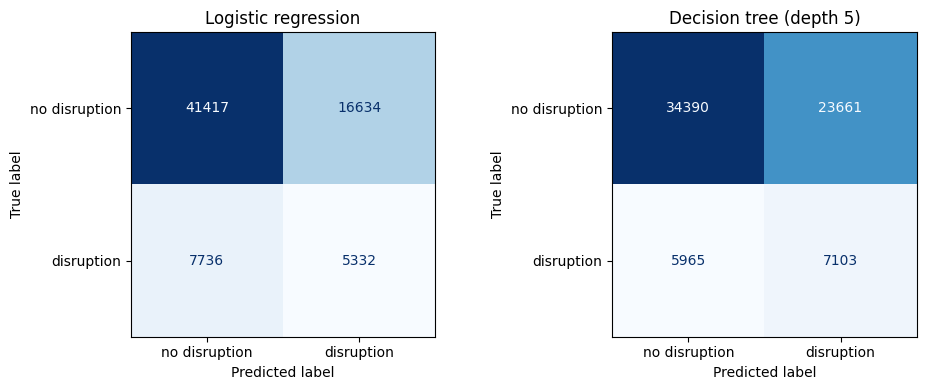

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, m) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_test, y_test, display_labels=['no disruption', 'disruption'],
                                          cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout(); plt.show()

## 4. Decision-tree feature importance

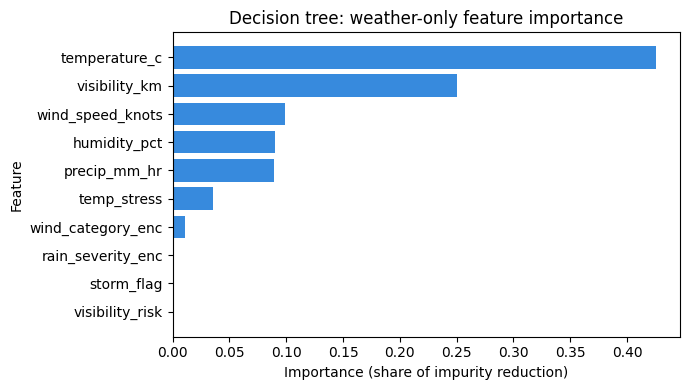

In [5]:
imp = pd.Series(models['Decision tree (depth 5)'].feature_importances_, index=WEATHER).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp.index, imp.values, color='#378ADD')
ax.set_xlabel('Importance (share of impurity reduction)'); ax.set_ylabel('Feature')
ax.set_title('Decision tree: weather-only feature importance')
plt.tight_layout(); plt.show()

## 5. What this tells us

In [6]:
best = max(rows[:2], key=lambda r: r['ROC-AUC'])
print('Best baseline on weather columns only: %s  (ROC-AUC %.3f, F1 of the disruption class %.3f)'
      % (best['model'], best['ROC-AUC'], best['F1 (disrupted)']))
print('A random guess has ROC-AUC 0.5 and an F1 of about %.2f for the disruption class when flagging everything.'
      % (2 * y_test.mean() / (1 + y_test.mean())))

Best baseline on weather columns only: Decision tree (depth 5)  (ROC-AUC 0.585, F1 of the disruption class 0.324)
A random guess has ROC-AUC 0.5 and an F1 of about 0.31 for the disruption class when flagging everything.


**Reading the result.** The pipeline works (labels, merge, split, evaluation). Weather alone separates disrupted from normal flights only a little better than chance: ROC-AUC about 0.58 and PR-AUC about 0.25 (a random model scores about 0.18), but the F1 of the disruption class (about 0.30-0.32) is no better than the trivial "flag every flight" rule (about 0.31). This is the baseline XGBoost has to beat, and it is a first sign that the F1 >= 0.70 target in the project report is not realistic. The weather here is correctly aligned with departure time (data quality report, Check 8), and the weak result is a property of the data: severe weather is rare and mostly acts through delays that have already built up, which weather-only models cannot see.

Note the models are trained with `class_weight='balanced'`, so their raw accuracy is not comparable to the "always no disruption" rule; compare ROC-AUC / PR-AUC instead.